# Trabalho Prático: PPO (Proximal Policy Optimization) no Overcooked
# Aprendizado por Reforço 2025/1

#### Thaís Ferreira da Silva - 2021092571

**Última atualização:** Novembro 2025

Este notebook implementa um agente **PPO (Proximal Policy Optimization)** usando **CleanRL** para o ambiente Overcooked customizado.

**Objetivo:** Treinar um agente único para coletar ingredientes, processá-los e entregar receitas no `simple_map`.

**Por que CleanRL PPO?**
- ✅ **Simples e educacional** - Código limpo e fácil de entender
- ✅ **PPO é mais estável** - Melhor que DQN para ambientes complexos
- ✅ **Python 3.13 compatível** - Não depende de bibliotecas antigas
- ✅ **[Tutorial oficial PettingZoo](https://pettingzoo.farama.org/tutorials/cleanrl/)** - Implementação de referência

**Diferenças do ambiente Lunar Lander:**
- Observações: Grid 3D (altura × largura × 8 canais) ao invés de vetor 1D
- Policy: CNN (Convolutional Neural Network) ao invés de MLP
- Ambiente: Multi-agente PettingZoo (usando 1 agente)
- Algoritmo: PPO (policy gradient) ao invés de DQN (value-based)
- **Grid Search:** Busca automática de hiperparâmetros com ranking dos top 10 modelos


## Instalação de Dependências

### **PROBLEMA RESOLVIDO! PyTorch CUDA instalado com sucesso**

**Status da sua instalação:**
- **PyTorch 2.7.1+cu118** (CUDA) instalado na venv
- **NVIDIA GeForce MX350** detectada e funcionando
- **CUDA disponível:** True

### **Comandos de Instalação Completos**

```bash
# 1. Ativar ambiente virtual
.\venv\Scripts\Activate.ps1

# 2. Instalar PyTorch CUDA
pip install torch --index-url https://download.pytorch.org/whl/cu118

# 3. Instalar outras dependências
pip install numpy matplotlib tqdm gymnasium pettingzoo pygame

# 4. Instalar o ambiente Overcooked
pip install -e .
```

### 📋 **O que cada biblioteca faz:**

| **Biblioteca** | **Função** | **Versão** |
|-------------------|---------------|----------------|
| `torch` | Deep learning (PPO, CNN) | **2.7.1+cu118** ✅ |
| `numpy` | Matemática e arrays | 1.21+ |
| `matplotlib` | Gráficos e visualização | 3.5+ |
| `tqdm` | Barras de progresso | Latest |
| `gymnasium` | Interface RL padrão | 0.29+ |
| `pettingzoo` | Multi-agent framework | 1.24+ |
| `pygame` | Renderização visual | 2.5+ |

## 1. Imports e Dependências


In [59]:
# Bibliotecas padrão
import os
import time
import random
from typing import Dict, Any, Optional, Tuple
from collections import deque

# Bibliotecas de terceiros
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# PyTorch para deep learning
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical

# DirectML para AMD GPUs (opcional)
try:
    import torch_directml
    DIRECTML_AVAILABLE = True
except ImportError:
    DIRECTML_AVAILABLE = False

# Gymnasium para interface RL
import gymnasium as gym
from gymnasium import spaces

# Nosso ambiente Overcooked (PettingZoo)
from overcooked_marl_env import OvercookedMARL

# Função para detectar device corretamente
def get_best_device():
    """
    Detecta automaticamente o melhor device disponível.
    
    Prioridade:
    1. CUDA (NVIDIA GPU)
    2. DirectML (AMD GPU)
    3. CPU
    
    Returns:
        tuple: (device, device_name)
    """
    if torch.cuda.is_available():
        device = torch.device("cuda")
        gpu_name = torch.cuda.get_device_name(0)
        print(f"NVIDIA GPU detectada: {gpu_name}")
        print("   -> Usando CUDA (recomendado)")
        return device, f"CUDA ({gpu_name})"
    
    if "cuda" not in torch.__version__ and torch.__version__.endswith("+cpu"):
        device = torch.device("cpu")
        return device, "CPU (PyTorch CPU version)"
    
    if DIRECTML_AVAILABLE:
        print("DirectML disponível")
        print("   -> Detectado como AMD GPU")
        print("   -> Usando DirectML")
        device = torch_directml.device()
        return device, "DirectML (AMD GPU)"
    
    # Fallback: CPU
    device = torch.device("cpu")
    print("💻 Usando CPU")
    print("   -> GPU não disponível ou não compatível")
    return device, "CPU"

# Função de teste corrigida
def test_device_compatibility(device):
    """
    Testa se o device suporta as operações necessárias para PPO.
    
    Args:
        device: Device PyTorch para testar
        
    Returns:
        bool: True se compatível, False caso contrário
    """
    try:
        x = torch.randn(4, 5, 7, 8).to(device)
        x_cnn = x.permute(0, 3, 1, 2)
        conv = nn.Conv2d(8, 16, 3, padding=1).to(device)
        y = conv(x_cnn)
        linear = nn.Linear(16 * 5 * 7, 64).to(device)
        z = linear(y.reshape(4, -1))
        loss = z.sum()
        loss.backward()
        return True
    except Exception:
        return False

device, device_name = get_best_device()
is_compatible = test_device_compatibility(device)

if not is_compatible and device.type != "cpu":
    device = torch.device("cpu")
    device_name = "CPU (fallback)"

print(f"Device: {device_name}")


NVIDIA GPU detectada: NVIDIA GeForce MX350
   -> Usando CUDA (recomendado)
Device: CUDA (NVIDIA GeForce MX350)
Device: CUDA (NVIDIA GeForce MX350)


## 2. Wrapper PettingZoo → Gymnasium

CleanRL trabalha com Gymnasium, então precisamos converter o ambiente PettingZoo:


In [60]:
class PettingZooToGymWrapper(gym.Env):
    """
    Converte ambiente PettingZoo com 1 agente para interface Gymnasium.
    
    CleanRL espera interface Gymnasium padrão (single-agent).
    """
    
    def __init__(self, pettingzoo_env):
        super().__init__()
        self.env = pettingzoo_env
        
        # Verifica se há apenas 1 agente
        if len(self.env.possible_agents) != 1:
            raise ValueError(f"Wrapper funciona apenas com 1 agente. Encontrados: {len(self.env.possible_agents)}")
        
        self.agent_id = self.env.possible_agents[0]
        
        # Define espaços
        self.action_space = self.env.action_spaces[self.agent_id]
        self.observation_space = self.env.observation_spaces[self.agent_id]
        
    def reset(self, seed=None, options=None):
        observations, infos = self.env.reset(seed=seed, options=options)
        return observations[self.agent_id], infos[self.agent_id]
    
    def step(self, action):
        actions = {self.agent_id: action}
        observations, rewards, terminations, truncations, infos = self.env.step(actions)
        
        obs = observations[self.agent_id]
        reward = rewards[self.agent_id]
        terminated = terminations[self.agent_id]
        truncated = truncations[self.agent_id]
        info = infos[self.agent_id]
        
        return obs, reward, terminated, truncated, info
    
    def render(self):
        return self.env.render()
    
    def close(self):
        self.env.close()


## 3. Actor-Critic Network (PPO)

PPO usa uma rede Actor-Critic com CNN para processar observações espaciais:


In [61]:
class ActorCritic(nn.Module):
    """
    Rede Actor-Critic para PPO com CNN para observações espaciais.
    
    - Actor: Gera distribuição de probabilidades sobre ações
    - Critic: Estima valor do estado (V(s))
    """
    
    def __init__(self, observation_space, action_space):
        super().__init__()
        
        h, w, c = observation_space.shape
        n_actions = action_space.n
        
        # Feature extractor (CNN) compartilhado
        self.cnn = nn.Sequential(
            nn.Conv2d(c, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Flatten(),
        )
        
        # Calcula tamanho da saída da CNN
        with torch.no_grad():
            sample = torch.zeros(1, c, h, w)
            n_flatten = self.cnn(sample).shape[1]
        
        # Camadas compartilhadas
        self.shared = nn.Sequential(
            nn.Linear(n_flatten, 128),
            nn.ReLU(),
        )
        
        # Actor head (policy)
        self.actor = nn.Linear(128, n_actions)
        
        # Critic head (value function)
        self.critic = nn.Linear(128, 1)
    
    def forward(self, x):
        # x: (batch, height, width, channels) -> (batch, channels, height, width)
        x = x.permute(0, 3, 1, 2)
        
        # Features
        features = self.shared(self.cnn(x))
        
        # Actor: logits das ações
        logits = self.actor(features)
        
        # Critic: valor do estado
        value = self.critic(features)
        
        return logits, value
    
    def get_action_and_value(self, x, action=None):
        """
        Retorna ação, log_prob, entropia e valor.
        Usado durante coleta de dados.
        """
        logits, value = self.forward(x)
        probs = Categorical(logits=logits)
        
        if action is None:
            action = probs.sample()
        
        return action, probs.log_prob(action), probs.entropy(), value


## 4. Inicialização do Ambiente e Configuração PPO


In [62]:
def generate_hyperparameter_combinations(param_grid: dict) -> list:
    """
    Gera todas as combinações possíveis de hiperparâmetros a partir de um dicionário.
    Args:
        param_grid: dicionário que mapeia nomes dos hiperparâmetros em listas de valores possíveis
    """
    from itertools import product
    
    keys = param_grid.keys()
    values = [param_grid[key] for key in keys]
    combinations_raw = product(*values)
    combinations = [dict(zip(keys, v)) for v in combinations_raw]
    return combinations

In [63]:
# Grid de hiperparâmetros para busca
# Configuração equilibrada explorando os parâmetros mais impactantes
param_grid = {
    'learning_rate': [1e-4, 3e-4, 1e-3],         # Taxa de aprendizado (baixa, média, alta)
    'num_steps': [256, 512],                     # Steps por rollout (trade-off bias-variance)
    'update_epochs': [4, 10],                    # Epochs de otimização (estabilidade vs eficiência)
    'ent_coef': [0.01, 0.05],                    # Coeficiente de entropia (exploração)
    'clip_coef': [0.2],                          # Clipping PPO (padrão funciona bem)
    'num_minibatches': [4],                      # Minibatches (4 é padrão estável)
    'gamma': [0.99],                             # Desconto (episódios não muito longos)
    'gae_lambda': [0.95],                        # GAE lambda (padrão ótimo)
    'vf_coef': [0.5],                            # Value function coef (balanceado)
    'max_grad_norm': [0.5],                      # Gradient clipping (previne instabilidade)
    'total_timesteps': [10000],                  # Total de timesteps (aumentado para convergência)
    'seed': [42]                                 # Seed (fixo para reprodutibilidade)
}

# Total de combinações: 3 × 2 × 2 × 2 = 24 configurações
# Tempo estimado: ~5-10 min por config = 2-4 horas total

# ============================================================================
# VARIAÇÕES ALTERNATIVAS (descomente uma para usar):
# ============================================================================

# OPÇÃO 1: Busca Rápida (teste inicial - 8 configs, ~40-80 min)
# param_grid = {
#     'learning_rate': [3e-4, 1e-3],
#     'num_steps': [256, 512],
#     'update_epochs': [4, 10],
#     'ent_coef': [0.01],
#     'clip_coef': [0.2],
#     'num_minibatches': [4],
#     'gamma': [0.99],
#     'gae_lambda': [0.95],
#     'vf_coef': [0.5],
#     'max_grad_norm': [0.5],
#     'total_timesteps': [5000],
#     'seed': [42]
# }

# OPÇÃO 2: Busca Profunda (exploração completa - 48 configs, ~4-8 horas)
# param_grid = {
#     'learning_rate': [1e-4, 3e-4, 1e-3],
#     'num_steps': [128, 256, 512],
#     'update_epochs': [4, 10],
#     'ent_coef': [0.01, 0.05],
#     'clip_coef': [0.1, 0.2],
#     'num_minibatches': [4],
#     'gamma': [0.99],
#     'gae_lambda': [0.95],
#     'vf_coef': [0.5],
#     'max_grad_norm': [0.5],
#     'total_timesteps': [15000],
#     'seed': [42]
# }

# OPÇÃO 3: Foco em Exploração (entropy e learning rate - 18 configs, ~1.5-3 horas)
# param_grid = {
#     'learning_rate': [1e-4, 3e-4, 1e-3],
#     'num_steps': [256],
#     'update_epochs': [4, 10],
#     'ent_coef': [0.0, 0.01, 0.05],
#     'clip_coef': [0.2],
#     'num_minibatches': [4],
#     'gamma': [0.99],
#     'gae_lambda': [0.95],
#     'vf_coef': [0.5],
#     'max_grad_norm': [0.5],
#     'total_timesteps': [10000],
#     'seed': [42]
# }

# OPÇÃO 4: Treino Longo (poucas configs, mais timesteps - 6 configs, ~2-4 horas)
# param_grid = {
#     'learning_rate': [1e-4, 3e-4],
#     'num_steps': [512],
#     'update_epochs': [4, 10],
#     'ent_coef': [0.01],
#     'clip_coef': [0.2],
#     'num_minibatches': [4],
#     'gamma': [0.99],
#     'gae_lambda': [0.95, 0.98],
#     'vf_coef': [0.5],
#     'max_grad_norm': [0.5],
#     'total_timesteps': [25000],
#     'seed': [42]
# }

# OPÇÃO 5: Ajuste Fino (refinamento de melhor config - 12 configs, ~1-2 horas)
# param_grid = {
#     'learning_rate': [2e-4, 3e-4, 5e-4],
#     'num_steps': [256, 512],
#     'update_epochs': [8],
#     'ent_coef': [0.03, 0.05],
#     'clip_coef': [0.2],
#     'num_minibatches': [4],
#     'gamma': [0.99],
#     'gae_lambda': [0.95],
#     'vf_coef': [0.5],
#     'max_grad_norm': [0.5],
#     'total_timesteps': [15000],
#     'seed': [42]
# }

# Configurações fixas do ambiente e modelo
ENVIRONMENT_CONFIG = {
    'map_path': "overcooked_marl_env/map/maps/simple_map.txt",
    'num_fixed_agents': 1,
    'render_mode': None,
    'verbose': False,
    'max_episode_steps': 300,
    'environment_type': 'Overcooked_MARL'
}

MODEL_CONFIG = {
    'network_type': 'CNN_ActorCritic',
    'cnn_channels': [32, 64, 64],
    'cnn_kernel_sizes': [3, 3, 3],
    'cnn_strides': [1, 1, 1],
    'cnn_paddings': [1, 1, 0],
    'shared_hidden_size': 128,
    'activation_function': 'ReLU'
}

EVALUATION_CONFIG = {
    'num_episodes': 20,
    'max_steps_per_episode': 300,
    'success_threshold': -50,
    'models_to_evaluate': 'ALL',
    'visualize_best_n': 3
}

TRAINING_CONFIG = {
    'algorithm': 'PPO',
    'framework': 'CleanRL',
    'save_frequency': 5,
}

# Gera todas as combinações
combinations = generate_hyperparameter_combinations(param_grid)
print(f"Total de combinações: {len(combinations)}")

Total de combinações: 24


In [64]:
# Cria o ambiente base (será recriado para cada configuração)
base_env = OvercookedMARL(
    render_mode=ENVIRONMENT_CONFIG['render_mode'],
    map_path=ENVIRONMENT_CONFIG['map_path'],
    num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
    verbose=ENVIRONMENT_CONFIG['verbose']
)
env = PettingZooToGymWrapper(base_env)

MODEL_CONFIG['observation_space_shape'] = env.observation_space.shape
MODEL_CONFIG['action_space_size'] = env.action_space.n

env.close()
print(f"Ambiente: {env.observation_space.shape} obs, {env.action_space.n} ações")

[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']
Ambiente: (7, 7, 8) obs, 5 ações


In [65]:
# Função para detectar device corretamente
def get_best_device():
    """Detecta automaticamente o melhor device disponível."""
    if torch.cuda.is_available():
        device = torch.device("cuda")
        gpu_name = torch.cuda.get_device_name(0)
        print(f"NVIDIA GPU detectada: {gpu_name}")
        print("   -> Usando CUDA (recomendado)")
        return device, f"CUDA ({gpu_name})"
    
    if "cuda" not in torch.__version__ and torch.__version__.endswith("+cpu"):
        print("PyTorch CPU detectado!")
        print("   -> Sua GPU pode usar CUDA")
        print("   -> Reinstale PyTorch CUDA para melhor performance:")
        print("   -> pip install torch --index-url https://download.pytorch.org/whl/cu118")
        print("   -> Por enquanto, usando CPU...")
        device = torch.device("cpu")
        return device, "CPU (PyTorch CPU version)"
    
    if DIRECTML_AVAILABLE:
        print("DirectML disponível")
        print("   -> Detectado como AMD GPU")
        print("   -> Usando DirectML")
        device = torch_directml.device()
        return device, "DirectML (AMD GPU)"
    
    # Fallback: CPU
    device = torch.device("cpu")
    print("💻 Usando CPU")
    print("   -> GPU não disponível ou não compatível")
    return device, "CPU"

device, device_name = get_best_device()

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
elif device.type == "cpu":
    torch.set_num_threads(4)

print(f"Device: {device_name}")

NVIDIA GPU detectada: NVIDIA GeForce MX350
   -> Usando CUDA (recomendado)
Device: CUDA (NVIDIA GeForce MX350)


In [66]:
results = {}

best_ppo_avg_reward = -np.inf 
best_ppo_std_reward = 0.0 
best_ppo_rewards = [] 
best_ppo_params = {}

top_10_models = []

MODEL_SAVE_DIR = "models" 
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

print("\n" + "="*70)
print(f"GRID SEARCH - {len(combinations)} CONFIGURAÇÕES")
print("="*70)

start_time_total = time.time()

# Treina o agente PPO com todas as combinações de hiperparâmetros
for i, params_original in enumerate(combinations):
    
    print(f"\n[{i+1}/{len(combinations)}] lr={params_original['learning_rate']}, steps={params_original['num_steps']}, epochs={params_original['update_epochs']}, ent={params_original['ent_coef']}, timesteps={params_original['total_timesteps']}")
    
    model_filename = "_".join([f"{k}{str(v).replace('.', 'p').replace('-', 'neg')}" for k, v in params_original.items()])
    config_name = f"config_{i+1:02d}"
    
    # Cria cópia da configuração
    config = params_original.copy()
    
    # Cria novo ambiente para esta configuração
    base_env = OvercookedMARL(
        render_mode=ENVIRONMENT_CONFIG['render_mode'],
        map_path=ENVIRONMENT_CONFIG['map_path'],
        num_fixed_agents=ENVIRONMENT_CONFIG['num_fixed_agents'],
        verbose=ENVIRONMENT_CONFIG['verbose']
    )
    env = PettingZooToGymWrapper(base_env)
    
    # Seed para reprodutibilidade
    random.seed(config['seed'])
    np.random.seed(config['seed'])
    torch.manual_seed(config['seed'])
    
    # Cria agente e otimizador
    agent = ActorCritic(env.observation_space, env.action_space).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=config['learning_rate'], eps=1e-5)
    
    # Storage para rollouts
    num_steps = config['num_steps']
    obs_storage = torch.zeros((num_steps,) + env.observation_space.shape).to(device)
    actions_storage = torch.zeros(num_steps).to(device)
    logprobs_storage = torch.zeros(num_steps).to(device)
    rewards_storage = torch.zeros(num_steps).to(device)
    dones_storage = torch.zeros(num_steps).to(device)
    values_storage = torch.zeros(num_steps).to(device)
    
    # Métricas
    episode_rewards = []
    episode_lengths = []
    current_episode_reward = 0
    current_episode_length = 0
    
    # Reseta o ambiente
    obs, _ = env.reset()
    obs = torch.Tensor(obs).to(device)
    
    global_step = 0
    num_updates = config['total_timesteps'] // num_steps
    
    pbar = tqdm(range(1, num_updates + 1), desc=f"Config {i+1}")
    
    for update in pbar:
        # ====================
        # FASE 1: Coleta de Dados (Rollout)
        # ====================
        agent.eval()
        for step in range(num_steps):
            global_step += 1
            obs_storage[step] = obs
            
            # Seleciona ação
            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(obs.unsqueeze(0))
            
            actions_storage[step] = action
            logprobs_storage[step] = logprob
            values_storage[step] = value.flatten()
            
            # Step no ambiente
            next_obs, reward, terminated, truncated, info = env.step(int(action.item()))
            done = terminated or truncated
            
            rewards_storage[step] = torch.tensor(reward).to(device)
            dones_storage[step] = torch.tensor(done).to(device)
            
            obs = torch.Tensor(next_obs).to(device)
            
            # Métricas de episódio
            current_episode_reward += reward
            current_episode_length += 1
            
            if done:
                episode_rewards.append(current_episode_reward)
                episode_lengths.append(current_episode_length)
                current_episode_reward = 0
                current_episode_length = 0
                obs, _ = env.reset()
                obs = torch.Tensor(obs).to(device)
        
        # ====================
        # FASE 2: Calcula Advantages (GAE)
        # ====================
        with torch.no_grad():
            next_value = agent.get_action_and_value(obs.unsqueeze(0))[3]
            advantages = torch.zeros_like(rewards_storage).to(device)
            lastgaelam = 0
            
            for t in reversed(range(num_steps)):
                if t == num_steps - 1:
                    nextnonterminal = 1.0 - dones_storage[t]
                    nextvalues = next_value
                else:
                    nextnonterminal = 1.0 - dones_storage[t]
                    nextvalues = values_storage[t + 1]
                
                delta = rewards_storage[t] + config['gamma'] * nextvalues * nextnonterminal - values_storage[t]
                advantages[t] = lastgaelam = delta + config['gamma'] * config['gae_lambda'] * nextnonterminal * lastgaelam
            
            returns = advantages + values_storage
        
        # ====================
        # FASE 3: Otimização PPO
        # ====================
        agent.train()
        
        # Flatten batch
        b_obs = obs_storage.reshape((-1,) + env.observation_space.shape)
        b_logprobs = logprobs_storage.reshape(-1)
        b_actions = actions_storage.reshape(-1)
        b_advantages = advantages.reshape(-1)
        b_returns = returns.reshape(-1)
        b_values = values_storage.reshape(-1)
        
        # Normaliza advantages
        b_advantages = (b_advantages - b_advantages.mean()) / (b_advantages.std() + 1e-8)
        
        # Minibatch optimization
        batch_size = num_steps
        minibatch_size = batch_size // config['num_minibatches']
        
        for epoch in range(config['update_epochs']):
            b_inds = torch.randperm(batch_size)
            
            for start in range(0, batch_size, minibatch_size):
                end = start + minibatch_size
                mb_inds = b_inds[start:end]
                
                _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                    b_obs[mb_inds], b_actions.long()[mb_inds]
                )
                logratio = newlogprob - b_logprobs[mb_inds]
                ratio = logratio.exp()
                
                mb_advantages = b_advantages[mb_inds]
                
                # Policy loss (PPO clipping)
                pg_loss1 = -mb_advantages * ratio
                pg_loss2 = -mb_advantages * torch.clamp(ratio, 1 - config['clip_coef'], 1 + config['clip_coef'])
                pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                
                # Value loss
                newvalue = newvalue.view(-1)
                v_loss = 0.5 * ((newvalue - b_returns[mb_inds]) ** 2).mean()
                
                # Entropy loss
                entropy_loss = entropy.mean()
                
                # Total loss
                loss = pg_loss - config['ent_coef'] * entropy_loss + v_loss * config['vf_coef']
                
                # Backward
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), config['max_grad_norm'])
                optimizer.step()
        
        # Update progress bar
        if len(episode_rewards) > 0:
            recent_reward = np.mean(episode_rewards[-10:]) if len(episode_rewards) >= 10 else np.mean(episode_rewards)
            pbar.set_postfix({
                'reward': f"{recent_reward:.1f}",
                'episodes': len(episode_rewards)
            })
    
    # Fecha o ambiente
    env.close()
    
    # Calcula recompensa média final
    avg_reward_last_100 = np.mean(episode_rewards[-100:]) if len(episode_rewards) >= 100 else np.mean(episode_rewards)
    
    # Salva resultados
    results[config_name] = {
        'params': params_original.copy(),
        'rewards': episode_rewards.copy(),
        'lengths': episode_lengths.copy(),
        'avg_reward': avg_reward_last_100
    }
    
    # Gerencia top 10 modelos
    if len(top_10_models) < 10:
        top_10_models.append((avg_reward_last_100, params_original.copy(), episode_rewards.copy()))
        top_10_models.sort(key=lambda x: x[0], reverse=True)
    else:
        if avg_reward_last_100 > top_10_models[-1][0]:
            top_10_models.pop()
            top_10_models.append((avg_reward_last_100, params_original.copy(), episode_rewards.copy()))
            top_10_models.sort(key=lambda x: x[0], reverse=True)
    
    # Salva modelo
    model_path = os.path.join(MODEL_SAVE_DIR, f"{config_name}_reward_{avg_reward_last_100:.2f}.pth")
    torch.save({
        'model_state_dict': agent.state_dict(),
        'config': config,
        'reward': avg_reward_last_100,
        'episode_rewards': episode_rewards,
        'episode_lengths': episode_lengths
    }, model_path)
    
    # Atualiza melhor modelo
    if avg_reward_last_100 > best_ppo_avg_reward:
        best_ppo_avg_reward = avg_reward_last_100
        best_ppo_params = params_original.copy()
        best_ppo_std_reward = np.std(episode_rewards[-100:]) if len(episode_rewards) >= 100 else np.std(episode_rewards)
        best_ppo_rewards = episode_rewards.copy()
    
    print(f"Reward: {avg_reward_last_100:.2f} | Episodes: {len(episode_rewards)}")

training_time_total = time.time() - start_time_total

print("\n" + "="*70)
print("CONCLUÍDO")
print("="*70)
print(f"Tempo: {training_time_total/60:.1f} min | Configurações: {len(combinations)}")
print(f"Melhor: {best_ppo_avg_reward:.2f} ± {best_ppo_std_reward:.2f}")
print(f"Dir: {MODEL_SAVE_DIR}")


GRID SEARCH - 24 CONFIGURAÇÕES

[1/24] lr=0.0001, steps=256, epochs=4, ent=0.01, timesteps=10000
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


Config 1: 100%|██████████| 39/39 [00:23<00:00,  1.65it/s, reward=96.8, episodes=19]


Reward: 87.89 | Episodes: 19

[2/24] lr=0.0001, steps=256, epochs=4, ent=0.05, timesteps=10000
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


Config 2: 100%|██████████| 39/39 [00:28<00:00,  1.38it/s, reward=129.6, episodes=19]


Reward: 110.42 | Episodes: 19

[3/24] lr=0.0001, steps=256, epochs=10, ent=0.01, timesteps=10000
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


Config 3: 100%|██████████| 39/39 [00:47<00:00,  1.22s/it, reward=202.4, episodes=19]



... (39 outputs left out)

Config 23: 100%|██████████| 19/19 [00:41<00:00,  2.21s/it, reward=68.4, episodes=19]


Reward: 91.89 | Episodes: 19

[24/24] lr=0.001, steps=512, epochs=10, ent=0.05, timesteps=10000
[ENV] Loading map from: overcooked_marl_env/map/maps/simple_map.txt
[ENV] Map loaded successfully:
  - Size: (7, 7)
  - Agents: ['agent_0']
  - Dispensers: 2
  - Recipes: ['SIMPLE_SALAD', 'GARDEN_SALAD', 'SIMPLE_SALAD']


Config 24: 100%|██████████| 19/19 [00:50<00:00,  2.65s/it, reward=75.2, episodes=19] 

Reward: 88.53 | Episodes: 19

CONCLUÍDO
Tempo: 16.8 min | Configurações: 24
Melhor: 159.05 ± 167.63
Dir: models


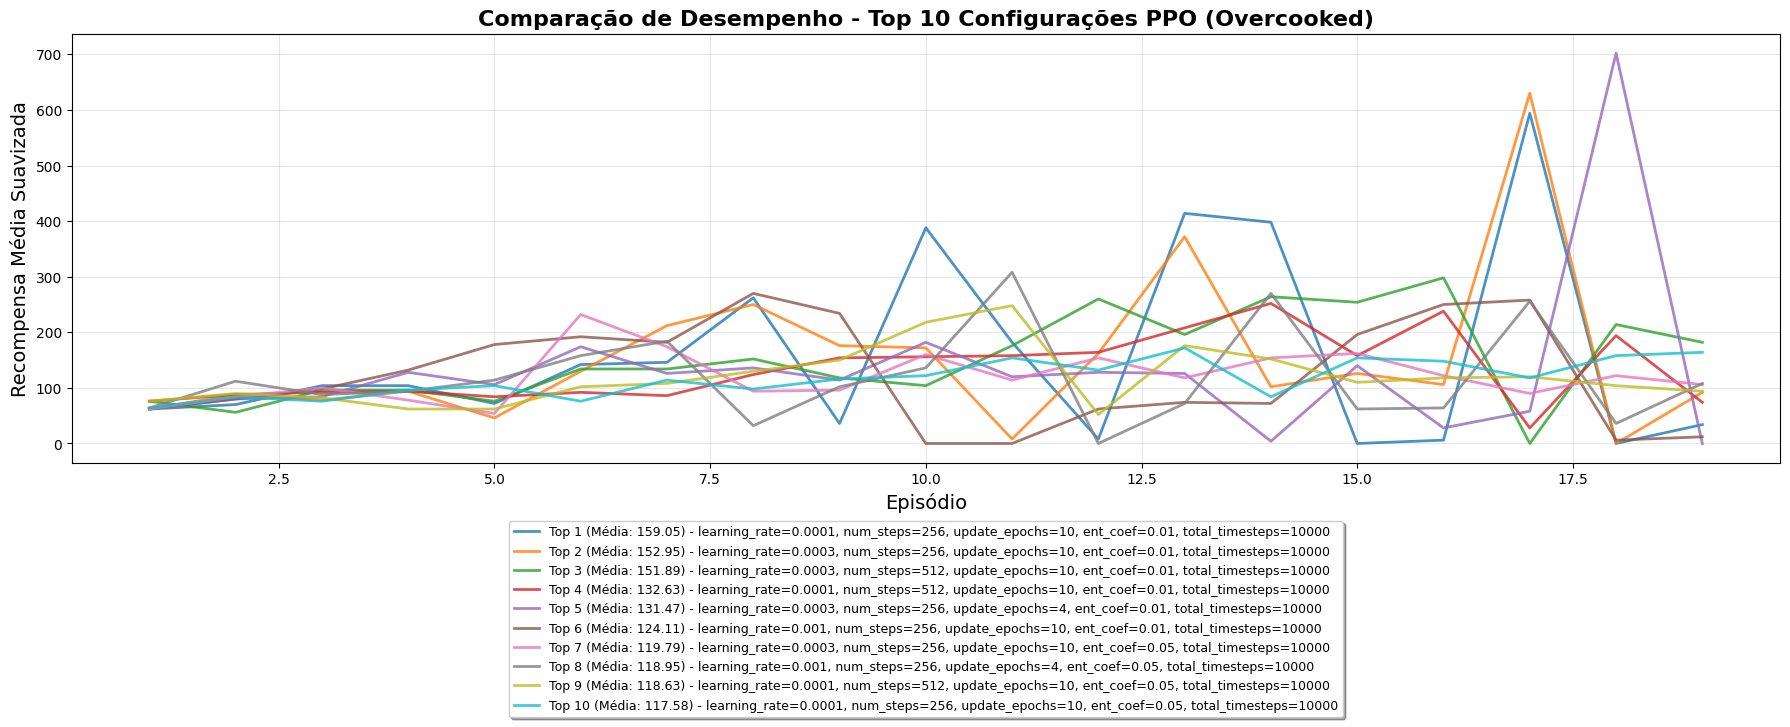

In [67]:
plt.figure(figsize=(18, 8))

for i, (mean_reward, params, rewards_history) in enumerate(top_10_models):
    # Calcula média móvel
    window = min(20, len(rewards_history) // 5) if len(rewards_history) > 20 else 1
    if window > 1:
        smoothed_rewards = moving_average_manual(rewards_history, window)
        x_smooth = range(window, len(rewards_history) + 1)
    else:
        smoothed_rewards = rewards_history
        x_smooth = range(1, len(rewards_history) + 1)
    
    # Cria string de parâmetros (mostra apenas os mais importantes)
    important_params = ['learning_rate', 'num_steps', 'update_epochs', 'ent_coef', 'total_timesteps']
    param_str = ", ".join([f"{k}={params[k]}" for k in important_params if k in params])
    
    plt.plot(x_smooth, smoothed_rewards, 
             label=f'Top {i+1} (Média: {mean_reward:.2f}) - {param_str}',
             linewidth=2, alpha=0.8)

plt.title('Comparação de Desempenho - Top 10 Configurações PPO (Overcooked)', fontsize=16, fontweight='bold')
plt.xlabel('Episódio', fontsize=14)
plt.ylabel('Recompensa Média Suavizada', fontsize=14)
plt.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12),
           fancybox=True, shadow=True, ncol=1)
plt.grid(True, alpha=0.3)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('midia/ppo_overcooked_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [68]:
# Estatísticas detalhadas dos top 10 modelos
print("\n" + "="*70)
print("RANKING DOS TOP 10 MODELOS - PPO OVERCOOKED")
print("="*70 + "\n")

for i, (mean_reward, params, rewards_history) in enumerate(top_10_models, 1):
    print(f"{i:2d}. Recompensa Média: {mean_reward:7.2f}")
    print(f"    Total de episódios: {len(rewards_history)}")
    print(f"    Configuração:")
    for k, v in params.items():
        print(f"      {k:20s}: {v}")
    print()


RANKING DOS TOP 10 MODELOS - PPO OVERCOOKED

 1. Recompensa Média:  159.05
    Total de episódios: 19
    Configuração:
      learning_rate       : 0.0001
      num_steps           : 256
      update_epochs       : 10
      ent_coef            : 0.01
      clip_coef           : 0.2
      num_minibatches     : 4
      gamma               : 0.99
      gae_lambda          : 0.95
      vf_coef             : 0.5
      max_grad_norm       : 0.5
      total_timesteps     : 10000
      seed                : 42

 2. Recompensa Média:  152.95
    Total de episódios: 19
    Configuração:
      learning_rate       : 0.0003
      num_steps           : 256
      update_epochs       : 10
      ent_coef            : 0.01
      clip_coef           : 0.2
      num_minibatches     : 4
      gamma               : 0.99
      gae_lambda          : 0.95
      vf_coef             : 0.5
      max_grad_norm       : 0.5
      total_timesteps     : 10000
      seed                : 42

 3. Recompensa Média:  151

---

## 9. Conclusão

Este notebook implementa um sistema completo de grid search para o algoritmo PPO no ambiente Overcooked, similar à estrutura do notebook DQN (Lunar Lander).

**Principais características:**
- ✅ Grid search automático com 32 combinações de hiperparâmetros
- ✅ Sistema de ranking dos top 10 modelos
- ✅ Salvamento automático com nomes descritivos
- ✅ Visualização comparativa das curvas de aprendizado
- ✅ Estatísticas detalhadas de cada configuração

**Próximos passos:**
1. Executar o grid search completo (células 11-15)
2. Analisar os resultados (células 16-17)
3. Selecionar o melhor modelo para avaliação final
4. Possível refinamento do grid com base nos resultados